In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('data/df_prob.csv')

In [21]:
df.duplicated().sum()


np.int64(0)

In [22]:
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estado_Civil,Posesion_Hipoteca,Personas_Cargo,Proposito,Fiador,Impago,Prima,Estudios_Doctorado,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Tiempo parcial,prob_pago,prob_impago,prediccion
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,2.0,1.0,1.0,Vivienda,0.0,0,65.85,0,0,0,0,1,0,0.392497,0.607503,1
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,1.0,1.0,1.0,Vivienda,0.0,0,260.60,0,0,1,0,0,0,0.348994,0.651006,1
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,1.0,0.0,1.0,Vivienda,1.0,0,221.02,0,1,0,0,0,0,0.659043,0.340957,0
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,1.0,0.0,1.0,Vivienda,0.0,0,125.00,0,1,0,0,0,0,0.495953,0.504047,1
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,2.0,0.0,1.0,Vivienda,0.0,0,800.00,0,0,0,0,0,0,0.433751,0.566249,1


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101895 entries, 0 to 101894
Data columns (total 26 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   ID                                   101895 non-null  object 
 1   Edad                                 101895 non-null  int64  
 2   Ingresos                             101895 non-null  float64
 3   Monto_Inicial                        101895 non-null  int64  
 4   Scoring_Crediticio                   101895 non-null  int64  
 5   Meses_Empleo                         101895 non-null  float64
 6   Num_Creditos                         101895 non-null  int64  
 7   Ratio_Interes                        101895 non-null  float64
 8   Duracion                             101895 non-null  float64
 9   Ratio_Deuda_Ingresos                 101895 non-null  float64
 10  Estado_Civil                         101895 non-null  float64
 11  Posesion_Hipo

In [24]:
df.columns

Index(['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio',
       'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion',
       'Ratio_Deuda_Ingresos', 'Estado_Civil', 'Posesion_Hipoteca',
       'Personas_Cargo', 'Proposito', 'Fiador', 'Impago', 'Prima',
       'Estudios_Doctorado', 'Estudios_Grado Universitario', 'Estudios_Máster',
       'Tipo_Jornada_Laboral_Autónomo', 'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Tiempo parcial', 'prob_pago', 'prob_impago',
       'prediccion'],
      dtype='object')

Observamos nuestra variable objetivo y vemos los nulos, valores unicos, las primas que sean 0 y las primas negativas. Por otro lado observamos la distribución de esta variable

In [25]:
print(df["Prima"].describe())
print(
)
print("Valores nulos:", df["Prima"].isnull().sum())
print("Valores únicos:", df["Prima"].nunique())
print("Valores iguales a cero:", (df["Prima"] == 0).sum())
print("Valores negativos:", (df["Prima"] < 0).sum())

count    101895.000000
mean        384.706766
std         267.147571
min          10.000000
25%         137.465000
50%         336.270000
75%         610.695000
max         800.000000
Name: Prima, dtype: float64

Valores nulos: 0
Valores únicos: 42158
Valores iguales a cero: 0
Valores negativos: 0


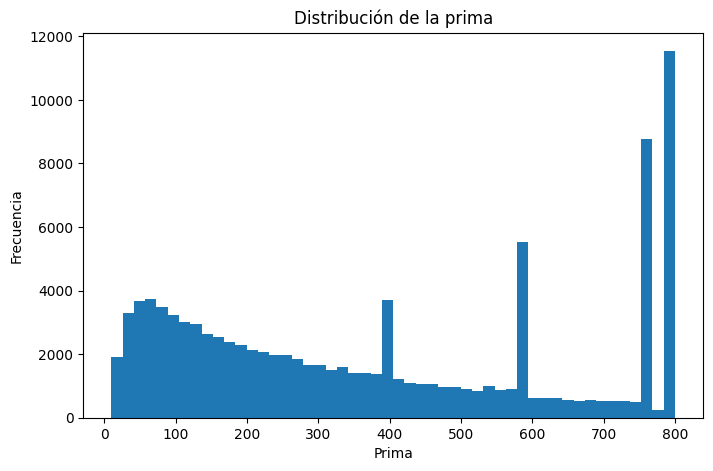

In [26]:
plt.figure(figsize=(8, 5))

plt.hist(df["Prima"], bins=50)

plt.xlabel("Prima")
plt.ylabel("Frecuencia")
plt.title("Distribución de la prima")

plt.show()

In [27]:
#### Hacemos un pairplot por cada variable categórica. Lo aplicamos para poder observar las variables que siguen una relación 
# polinómica mediante la 'curva' que podemos llegar a observar en los distintos gráficos, en los cuales compara la variable
# categórica seleccionada con todas las variables numéricas.

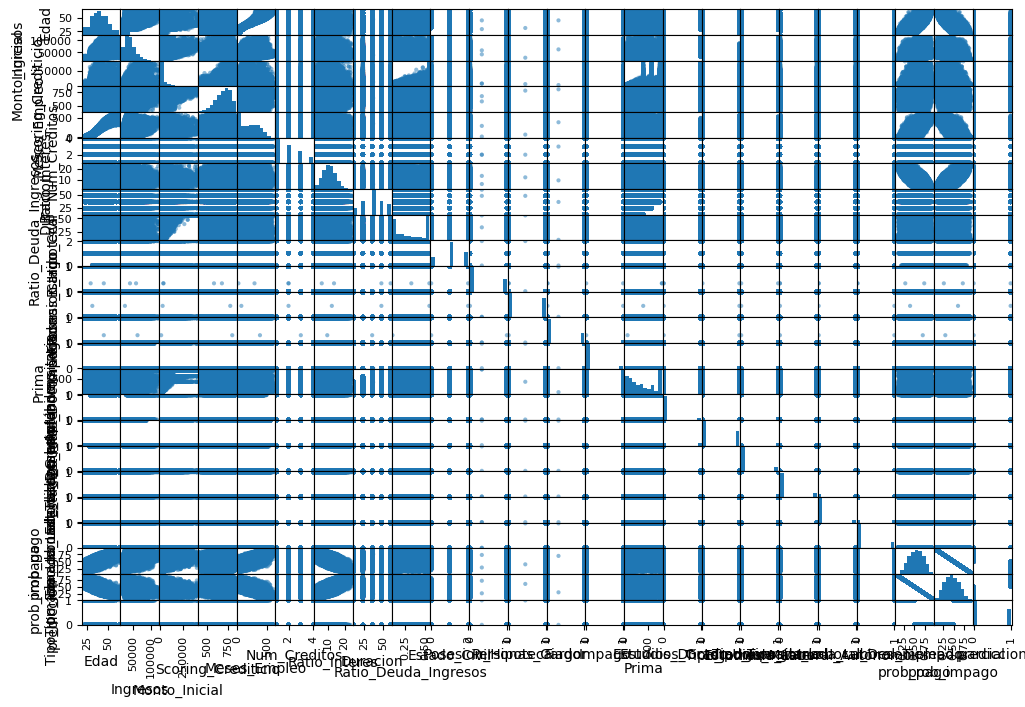

In [28]:
from pandas.plotting import scatter_matrix
scatter_matrix(df, figsize=(12, 8))
plt.show()

In [29]:
# sns.pairplot(df)

In [30]:
correlaciones = (
    df.select_dtypes(include="number")
      .corr()["Prima"]
      .drop("Prima")
      .sort_values(key=abs, ascending=False)
)

display(correlaciones.to_frame(name="Correlacion_con_Prima"))

,Correlacion_con_Prima
Ratio_Deuda_Ingresos,0.636085
Monto_Inicial,0.626538
Duracion,0.305995
Ingresos,0.222311
Ratio_Interes,0.139729
Edad,0.115464
Estado_Civil,-0.096761
Estudios_Doctorado,0.095346
Estudios_Máster,0.084178
Meses_Empleo,0.080449


In [31]:
### Observamos que tenemos las primas de todos los usuarios y que todos son mayores a 0, por lo que deducimos que tenemos
# valores 'reales'

In [32]:
### El siguiente paso que se lleva a cabo es la observación gráifca de la correlación entre las 2 variables más correlacionadas
# con la prima, 'Ratio_Deuda_Ingresos' y 'Monto_Inicial'


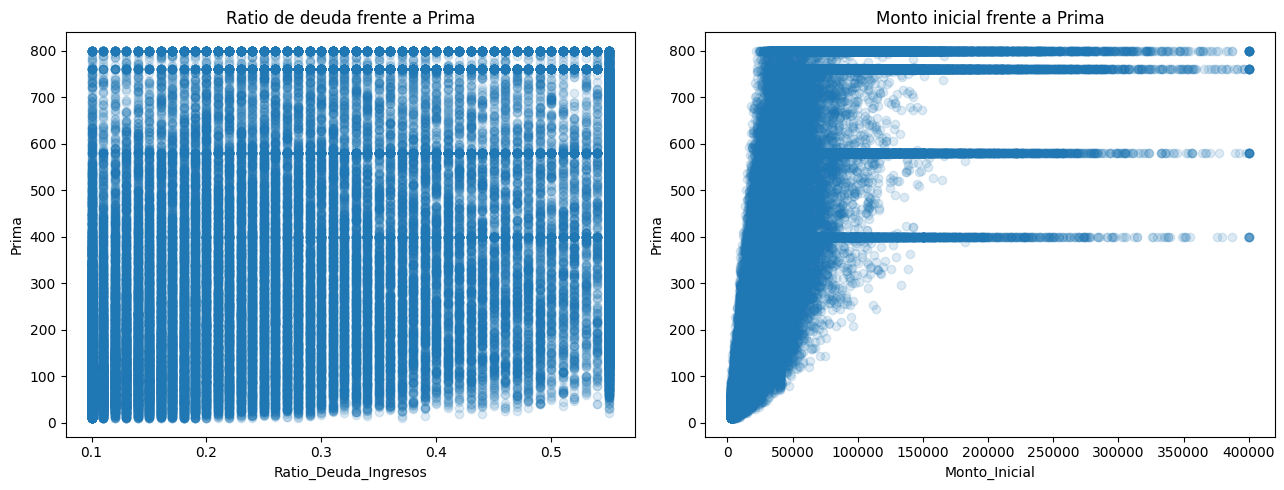

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    df["Ratio_Deuda_Ingresos"],
    df["Prima"],
    alpha=0.15
)
axes[0].set_xlabel("Ratio_Deuda_Ingresos")
axes[0].set_ylabel("Prima")
axes[0].set_title("Ratio de deuda frente a Prima")

axes[1].scatter(
    df["Monto_Inicial"],
    df["Prima"],
    alpha=0.15
)
axes[1].set_xlabel("Monto_Inicial")
axes[1].set_ylabel("Prima")
axes[1].set_title("Monto inicial frente a Prima")

plt.tight_layout()
plt.show()

In [34]:
### La variable 'Ratio_Deuda_Ingresos' tiene una asociación lineal relativamente fuerte con 'Prima', pero por sí sola 
# no determina la prima.
### La correlación de 0,627 indica una asociación positiva importante. Sin embargo, las franjas horizontales podrían indicar 
# valores de prima repetidos, límites o algún proceso de generación de los datos.

División de los datos en train y test

In [35]:
### Hacemos train/test con las variables más correlacionadas según el método Pearson

In [36]:
from sklearn.model_selection import train_test_split

X = df[['Ratio_Deuda_Ingresos', 'Monto_Inicial', 'Duracion', 'Ingresos', 'prob_pago']] 
y = df[["Prima"]]

X_train, X_test, y_train, y_test = train_test_split(
                                        X, y,
                                        train_size = 0.8,
                                        random_state = 42,
                                        shuffle = True)


Estantarizamos los datos del train

In [37]:
from sklearn.preprocessing import StandardScaler

# Crear el estandarizador
scaler = StandardScaler()

# Aprender la media y desviación típica SOLO del entrenamiento
X_train_scaled = scaler.fit_transform(X_train)

# Aplicar esa misma transformación al conjunto de prueba
X_test_scaled = scaler.transform(X_test)

In [38]:
from sklearn.linear_model import LinearRegression

modelo_lineal = LinearRegression()

modelo_lineal.fit(X_train_scaled, y_train)

y_pred_lineal = modelo_lineal.predict(X_test_scaled)

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calcular métricas
mae = mean_absolute_error(y_test, y_pred_lineal)
mse = mean_squared_error(y_test, y_pred_lineal)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lineal)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 131.73552951405102
MSE: 27296.980661743164
RMSE: 165.217979232719
R²: 0.6174628204641974
